In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np 
from prophet import Prophet

In [3]:
Combined_final = pd.read_csv('Final_cleanedDataset.csv')
len(Combined_final)
Combined_final.head()

,Job_Title,Work_mode,Posting_date,Skills,Country,date
0,AI Engineer,Remote,2024-06-01,Deep Learning,Canada,2024-06-01
1,Data Engineer,On-site,2024-11-01,"Python, Cloud",United States,2024-11-01
2,AI Engineer,Hybrid,2024-03-01,Cloud,Germany,2024-03-01
3,Data Scientist,On-site,2024-03-01,"Python, SQL, Machine Learning, Cloud",Canada,2024-03-01
4,Data Scientist,Remote,2024-12-01,"SQL, Deep Learning",Singapore,2024-12-01


In [14]:
Combined_final['Posting_date'] = pd.to_datetime(Combined_final['Posting_date'])

ts_fprophet = (
    Combined_final.set_index('Posting_date')
    .resample('MS')
    .size()
    .rename('y')
    .reset_index()
    .rename(columns={'Posting_date': 'ds'})
)

ts_fprophet['y'] = ts_fprophet['y'].fillna(0)

print("Prophet input preview:")
print(ts_fprophet.head())

Prophet input preview:
          ds    y
0 2021-01-01  711
1 2021-02-01  579
2 2021-03-01  750
3 2021-04-01  988
4 2021-05-01  927


In [16]:
split_idx = int(len(ts_fprophet) * 0.80)
train_prophet = ts_fprophet.iloc[:split_idx].copy()
test_prophet = ts_fprophet.iloc[split_idx:].copy()

prophet_model = Prophet(
    yearly_seasonality=True,     # Models recurring 12-month annual cycles
    weekly_seasonality=False,    # Monthly data: weekly seasonality must be False
    daily_seasonality=False,
    seasonality_mode='multiplicative', # Scales seasonal swings relative to trend growth
    interval_width=0.95          # 95% uncertainty interval
)

prophet_model.fit(train_prophet)

23:49:56 - cmdstanpy - INFO - Chain [1] start processing
23:49:57 - cmdstanpy - INFO - Chain [1] done processing


In [19]:
# DataFrame for test window
future_test = prophet_model.make_future_dataframe(periods=len(test_prophet), freq='MS')
forecast_test = prophet_model.predict(future_test)

#test window metrics
test_pred = forecast_test.iloc[-len(test_prophet):].copy()

evaluation_prophet = pd.DataFrame({
    'Actual_Postings': test_prophet['y'].values,
    'Forecasted_Postings': test_pred['yhat'].round().values,
    'Lower_95_CI': test_pred['yhat_lower'].round().clip(lower=0).values,
    'Upper_95_CI': test_pred['yhat_upper'].round().values
}, index=test_prophet['ds'])

rmse_prophet = np.sqrt(np.mean((evaluation_prophet['Actual_Postings'] - evaluation_prophet['Forecasted_Postings']) ** 2))
mape_prophet = np.mean(np.abs((evaluation_prophet['Actual_Postings'] - evaluation_prophet['Forecasted_Postings']) / evaluation_prophet['Actual_Postings'])) * 100

print("\n--- 20% Test Performance (Prophet) ---")
print(evaluation_prophet)
print(f"\nProphet Test RMSE: {rmse_prophet:.2f}")
print(f"Prophet Test MAPE: {mape_prophet:.2f}%")



--- 20% Test Performance (Prophet) ---
            Actual_Postings  Forecasted_Postings  Lower_95_CI  Upper_95_CI
ds                                                                        
2025-05-01              826                659.0        208.0       1107.0
2025-06-01              900                672.0        209.0       1096.0
2025-07-01              882                719.0        303.0       1165.0
2025-08-01             1054                742.0        302.0       1192.0
2025-09-01             1043                781.0        379.0       1211.0
2025-10-01             1355                741.0        295.0       1140.0
2025-11-01             1407                824.0        411.0       1284.0
2025-12-01             1665                689.0        260.0       1083.0
2026-01-01              274                804.0        368.0       1226.0
2026-02-01              305                679.0        250.0       1104.0
2026-03-01              468                706.0        277.

In [22]:
#entire 6-year history
full_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False,
    seasonality_mode='multiplicative',
    interval_width=0.95
)
full_model.fit(ts_fprophet)

#Generate future grid for 24 months (2 years)
future_2yr = full_model.make_future_dataframe(periods=24, freq='MS')
forecast_2yr = full_model.predict(future_2yr)

#Extract the 24 future months
future_slice = forecast_2yr.iloc[-24:].copy()

# Enforce a 40% floor so Lower_95_CI avoids zero collapse
lowest_floor = (future_slice['yhat'] * 0.4).round().values

two_year_forecast_prophet = pd.DataFrame({
    'Forecasted_Postings': future_slice['yhat'].round().values,
    'Lower_95_CI': np.maximum(future_slice['yhat_lower'].round().values, lowest_floor),
    'Upper_95_CI': future_slice['yhat_upper'].round().values
}, index=future_slice['ds'])

print("\n2-Year Future Forecast (24 Months Ahead - Prophet):")
print(two_year_forecast_prophet)

23:53:07 - cmdstanpy - INFO - Chain [1] start processing
23:53:07 - cmdstanpy - INFO - Chain [1] done processing



2-Year Future Forecast (24 Months Ahead - Prophet):
            Forecasted_Postings  Lower_95_CI  Upper_95_CI
ds                                                       
2026-06-01                774.0        310.0       1300.0
2026-07-01                806.0        322.0       1337.0
2026-08-01                903.0        393.0       1398.0
2026-09-01                862.0        363.0       1384.0
2026-10-01                948.0        465.0       1496.0
2026-11-01                966.0        440.0       1475.0
2026-12-01                941.0        430.0       1451.0
2027-01-01                858.0        401.0       1380.0
2027-02-01                690.0        276.0       1235.0
2027-03-01                730.0        292.0       1258.0
2027-04-01                762.0        317.0       1270.0
2027-05-01                754.0        302.0       1252.0
2027-06-01                770.0        308.0       1300.0
2027-07-01                806.0        325.0       1305.0
2027-08-01         

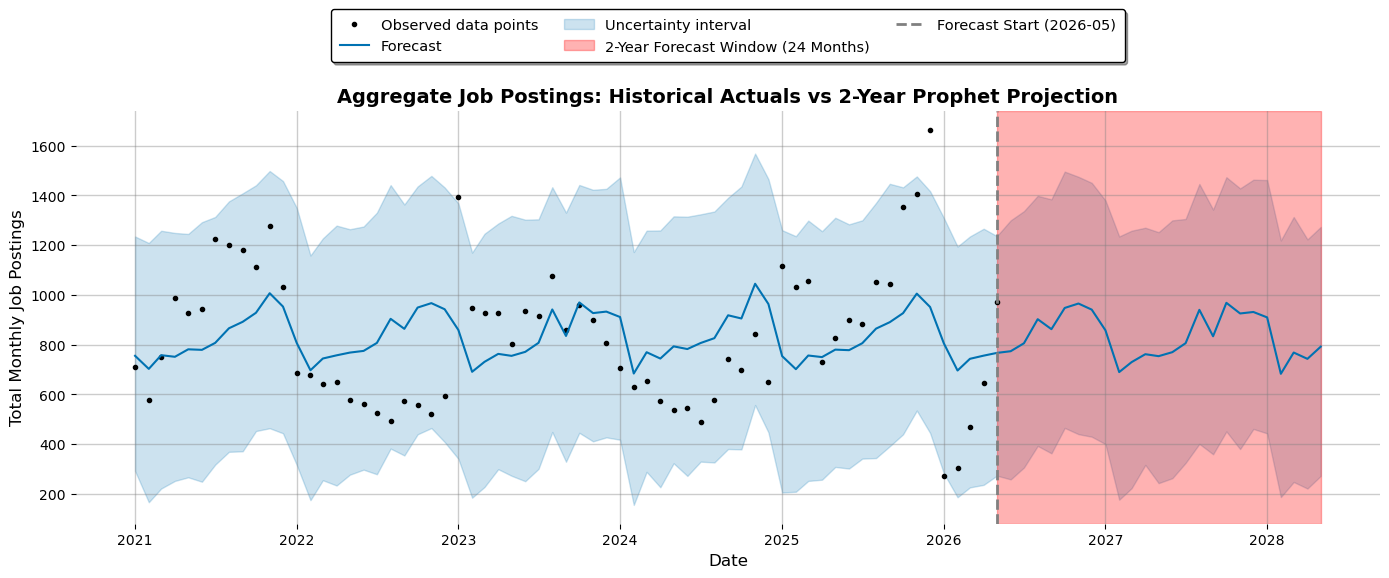

In [72]:
#Main forecast trajectory
fig1 = full_model.plot(forecast_2yr, figsize=(14, 6))
ax = fig1.gca()
forecast_start = ts_fprophet['ds'].max()
forecast_end = forecast_2yr['ds'].max()

split_date = ts_fprophet['ds'].max()

ax.axvspan(
    xmin=forecast_start,
    xmax=forecast_end,
    color='red',
    alpha=0.3,
    label='2-Year Forecast Window (24 Months)'
)

ax.axvline(
    x=split_date,
    color='gray',
    linestyle='--',
    linewidth=2,
    label=f'Forecast Start ({split_date.strftime("%Y-%m")})'
)

plt.title('Aggregate Job Postings: Historical Actuals vs 2-Year Prophet Projection', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Total Monthly Job Postings', fontsize=12)
    
legend = ax.legend(
    loc='lower center',
    bbox_to_anchor=(0.5, 1.1),
    ncol=3,
    frameon=True,
    fancybox=True,             
    shadow=True,               
    facecolor='white',      
    edgecolor='black',       
    fontsize=10.5,
    borderpad=0.6,
    handletextpad=0.8,
    columnspacing=1.8
)
    
#plt.legend(loc='upper left', fontsize=10, frameon=True)
plt.grid(True, alpha=0.4)
plt.box(False)
plt.tight_layout()
plt.show()

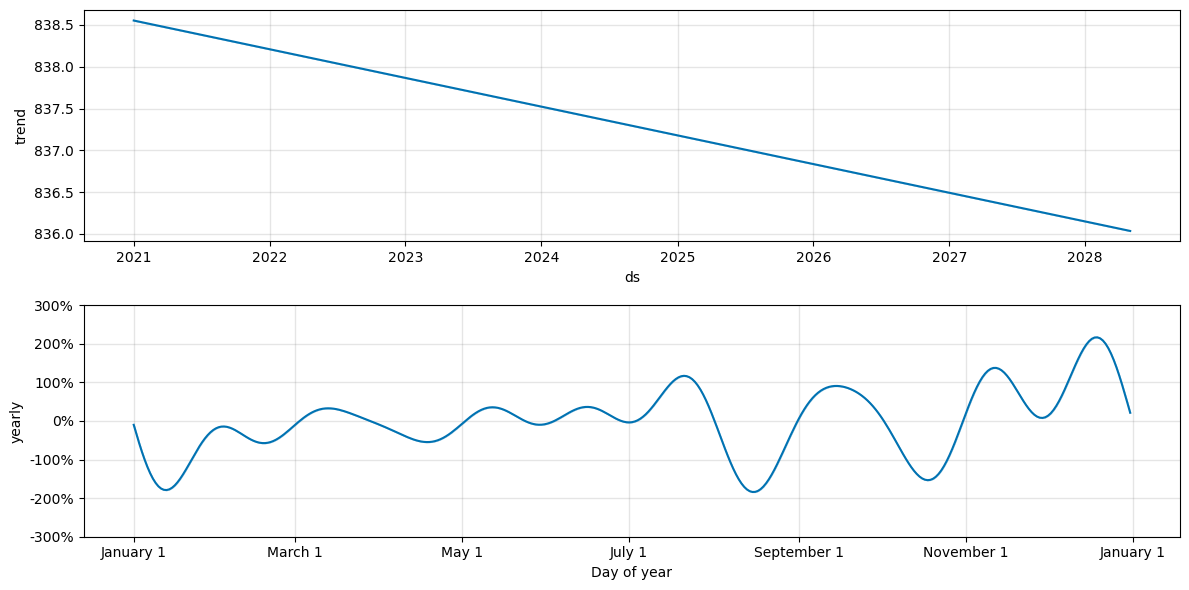

In [41]:
fig2 = full_model.plot_components(forecast_2yr, figsize=(12, 6))
plt.show()